Start a new project : Fashion-MNIST Classification

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [3]:
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

In [4]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
train_df.shape

(60000, 785)

In [10]:
train_df.isnull().sum().sum()

np.int64(0)

In [11]:
test_df.isnull().sum().sum()

np.int64(0)

In [12]:
train_df['label'].value_counts()

label
2    6000
9    6000
6    6000
0    6000
3    6000
4    6000
5    6000
8    6000
7    6000
1    6000
Name: count, dtype: int64

<Axes: xlabel='label'>

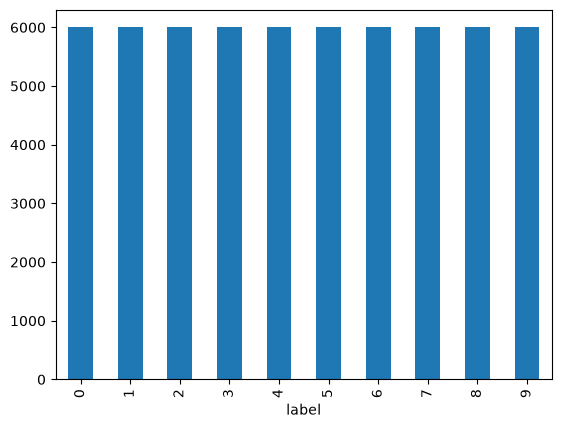

In [14]:
train_df['label'].value_counts().sort_index().plot(kind= 'bar')

Preprocessing

In [15]:
X_train = train_df.drop('label', axis= 1)
y_train = train_df['label']

X_test = test_df.drop('label', axis= 1)
y_test = test_df['label']

Image reshaping

In [16]:
X_train = X_train.astype('float32')/255.0
X_test = X_test.astype('float32')/255.0

In [23]:
X_train = X_train.reshape(-1, 28, 28, 1)

X_test = X_test.to_numpy().reshape(-1, 28, 28, 1)

In [24]:
print(X_train.shape)
print(X_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


ANN

In [25]:
X_train_ann = X_train.reshape(-1, 784)
X_test_ann = X_test.reshape(-1, 784)

In [42]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from sklearn.metrics import accuracy_score

In [37]:
ann = Sequential([
    tf.keras.Input(shape=(784,)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [40]:
ann.compile(optimizer='adam', loss= 'sparse_categorical_crossentropy', metrics=['accuracy'])

In [41]:
ann_history = ann.fit(
    X_train_ann,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8175 - loss: 0.5127 - val_accuracy: 0.8535 - val_loss: 0.4179
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8627 - loss: 0.3788 - val_accuracy: 0.8683 - val_loss: 0.3757
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8746 - loss: 0.3414 - val_accuracy: 0.8698 - val_loss: 0.3622
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.8832 - loss: 0.3185 - val_accuracy: 0.8788 - val_loss: 0.3310
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8905 - loss: 0.2995 - val_accuracy: 0.8837 - val_loss: 0.3291
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8921 - loss: 0.2888 - val_accuracy: 0.8683 - val_loss: 0.3575
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.8984 - loss: 0.2727 - val_accuracy: 0.8858 - val_loss: 0.3249
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9000 - loss: 0.2639 - 

In [44]:
acc_ann = ann.evaluate(X_test_ann, y_test, verbose= 0)[1]

In [45]:
acc_ann

0.8873999714851379